<a href="https://colab.research.google.com/github/Wistoo/2026-CS420-01/blob/main/Assigment_3.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Assignment 3: SLCM Classification Analysis
## CS430
## Wiston Htoo
## 11/05/2026


# Goal
#### In Assignment 2, you predicted the amount of overdue rent. Now the question is: Can household and housing information help identify households with $3,000 or more in past-due rent? Apply five classification models using the same prepared data. Focus on a fair comparison and a clear explanation of the results rather than complicated tuning.


# Notebook Instructions
* Copy each numbered question into a Markdown cell; answer beneath it in small code or Markdown cells.
* After important outputs and the chart, write 1–3 sentences of interpretation.
* Use the same 80/20 train/test split for all five models: test_size=0.20, random_state=42, stratify=y.
* Use the same preprocessing pipeline for each model; you may reuse the example from class.
* Do not use record_id or past_due_rent as model inputs. Run all cells and keep outputs visible.



# Part 1 – Understand the Classification Problem (15 points)


## 1. Explore the dataset (7 points)

In [45]:
import pandas as pd

# Load the CSV
df = pd.read_csv('/content/SLCM_rent_arrears_student_clean (1).csv')


In [46]:
# Display five rows
display(df.head())

,record_id,adults_in_household,children_in_household,household_has_65plus,monthly_household_income,income_sources,employment_status,has_housing_voucher,eviction_in_progress,behind_on_utilities,main_reason_behind_on_rent,intake_quarter,monthly_rent,past_due_rent
0,SLCM_0001,1,1,No,293.0,"Food benefits - TANF/SNAP, No income, Other",Unemployed but want to find work,No,I don't know,Yes,Other,2026-Q1,1560.0,3100.0
1,SLCM_0002,0,3,No,2000.0,Child support,Employed,No,I don't know,Yes,Unexpected expense,2026-Q3,1550.0,7300.0
2,SLCM_0003,1,0,No,400.0,Food benefits - TANF/SNAP,Unemployed but want to find work,I don't know,Yes,Yes,Lost a job/had hours cut,2025-Q4,0.0,6000.0
3,SLCM_0004,2,0,No,2500.0,Full-time employment,Unemployed and not looking for work,No,Yes,Yes,Lost a job/had hours cut,2026-Q2,1299.0,2500.0
4,SLCM_0005,1,2,No,14.0,Part-time employment,Employed,No,Yes,No,Unexpected expense,2025-Q4,1105.5,1205.5


In [47]:
# Display data shape
print("Data Shape:", df.shape)

Data Shape: (1754, 14)


In [48]:
# Display column names
print("\nColumn Names:")
print(df.columns.tolist())


Column Names:
['record_id', 'adults_in_household', 'children_in_household', 'household_has_65plus', 'monthly_household_income', 'income_sources', 'employment_status', 'has_housing_voucher', 'eviction_in_progress', 'behind_on_utilities', 'main_reason_behind_on_rent', 'intake_quarter', 'monthly_rent', 'past_due_rent']


In [49]:
# Display missing-value counts
print("\nMissing-Value Counts:")
print(df.isnull().sum())


Missing-Value Counts:
record_id                       0
adults_in_household             0
children_in_household           0
household_has_65plus            0
monthly_household_income      108
income_sources                  0
employment_status               0
has_housing_voucher             0
eviction_in_progress            1
behind_on_utilities             7
main_reason_behind_on_rent     16
intake_quarter                  0
monthly_rent                    8
past_due_rent                   0
dtype: int64


In [50]:
# Identify one numerical and one categorical feature.
numerical_feature = 'past_due_rent'
categorical_feature = 'high_arrears'

#### Answer: Why must past_due_rent be excluded from the input features?

We must exclude **past_due_rent** from the input features to prevent **data leakage** (or target leakage). Because our target variable **high_arrears** is directly derived from **past_due_rent** (i.e., whether it is >= $3,000), including it would give the model the direct answer. The model would just learn this threshold rule rather than finding patterns in the other household and housing characteristics.


## 2. Create the target (8 points)


In [51]:
# Create high_arrears: 1 if past_due_rent is at least $3,000, otherwise 0.
df['high_arrears'] = (df['past_due_rent'] >= 3000).astype(int)

Class Counts:
high_arrears
0    1210
1     544
Name: count, dtype: int64


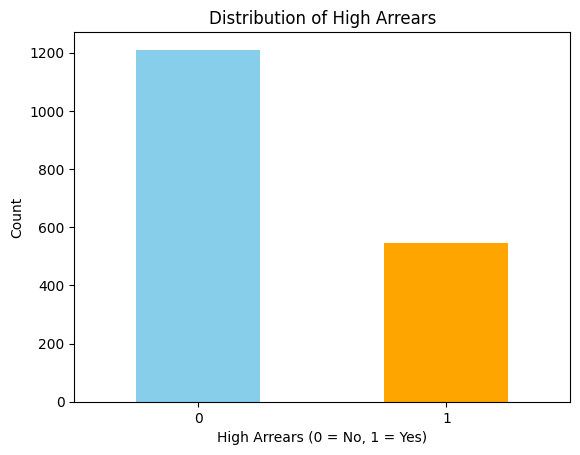

In [52]:
import matplotlib.pyplot as plt

# Show class counts and one bar chart of high_arrears.
class_counts = df['high_arrears'].value_counts()
print("Class Counts:")
print(class_counts)

# Plot bar chart
class_counts.plot(kind='bar', color=['skyblue', 'orange'])
plt.title('Distribution of High Arrears')
plt.xlabel('High Arrears (0 = No, 1 = Yes)')
plt.ylabel('Count')
plt.xticks(rotation=0)
plt.show()

#### Answer: Which class is larger? Why might accuracy alone be misleading?

Class 0 (not high arrears) is the larger class with 1,210 instances, while Class 1 (high arrears) has 544 instances.

Accuracy alone can be misleading because the dataset is imbalanced. Since roughly 69% (1210/1754) of the cases belong to Class 0, a "dummy" model that just predicts 0 every time would achieve 69% accuracy. It would look like a decent model, but it would completely fail to identify any of the high-arrears households (Class 1) that SLCM is trying to find.

# Part 2 – Prepare the Data (25 points)

## 3. Select features and split (10 points)

In [53]:
# Create X by dropping record_id, past_due_rent, and high_arrears. Set y = high_arrears.
X = df.drop(columns=['record_id', 'past_due_rent', 'high_arrears'])
y = df['high_arrears']

In [54]:
# Split the data once into training and testing sets.
from sklearn.model_selection import train_test_split

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.20, random_state=42, stratify=y
)

print(f"Training set shape: X_train={X_train.shape}, y_train={y_train.shape}")
print(f"Testing set shape: X_test={X_test.shape}, y_test={y_test.shape}")

Training set shape: X_train=(1403, 12), y_train=(1403,)
Testing set shape: X_test=(351, 12), y_test=(351,)


#### Answer: Why do we keep a separate test set?

We keep a separate test set to evaluate how well our model generalizes to new, unseen data. If we test the model on the same data it was trained on, it might simply memorize the answers (overfitting), giving us a false sense of how well it will perform in the real world.

## 4. Build one reusable preprocessor (15 points)



In [55]:
# Identify numerical and categorical columns with select_dtypes.
from sklearn.pipeline import Pipeline
from sklearn.compose import ColumnTransformer
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler, OneHotEncoder

numeric_features = X_train.select_dtypes(include=['int64', 'float64']).columns.tolist()
categorical_features = X_train.select_dtypes(include=['object', 'category']).columns.tolist()

print("Numeric Features:", numeric_features)
print("Categorical Features:", categorical_features)

Numeric Features: ['adults_in_household', 'children_in_household', 'monthly_household_income', 'monthly_rent']
Categorical Features: ['household_has_65plus', 'income_sources', 'employment_status', 'has_housing_voucher', 'eviction_in_progress', 'behind_on_utilities', 'main_reason_behind_on_rent', 'intake_quarter']


In [56]:
# Numerical: fill missing values using median and apply StandardScaler.
numeric_transformer = Pipeline(steps=[
    ('imputer', SimpleImputer(strategy='median')),
    ('scaler', StandardScaler())
])

In [57]:
# Categorical: fill missing values using mode and apply OneHotEncoder.
categorical_transformer = Pipeline(steps=[
    ('imputer', SimpleImputer(strategy='most_frequent')),
    ('onehot', OneHotEncoder(handle_unknown='ignore'))
])

In [58]:
# Combine them into a single preprocessor.
preprocessor = ColumnTransformer(
    transformers=[
        ('num', numeric_transformer, numeric_features),
        ('cat', categorical_transformer, categorical_features)
    ])

#### Answer: Why is scaling helpful for KNN and SVC?

Scaling is crucial for distance-based algorithms like KNN and SVC because they rely on calculating distances (such as Euclidean distance) between data points to make predictions. If features are on different scales (for instance, `monthly_household_income` might be in the thousands, while `adults_in_household` is a small single-digit number), the features with larger numeric ranges will completely dominate the distance calculations. Standardizing or scaling the data ensures that all features contribute equally to the model's decision-making process.

# Part 3 – Train and Compare Five Models (45 points)

## 5. Train the five classifiers (20 points)

Build five pipelines with the same preprocessor, the same training set, and these models:

### Logistic Regression:

In [59]:
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score, recall_score, f1_score

lr_pipe = Pipeline(steps=[('preprocessor', preprocessor), ('classifier', LogisticRegression(max_iter=1000))])
lr_pipe.fit(X_train, y_train)
y_pred = lr_pipe.predict(X_test)
print("Accuracy:", accuracy_score(y_test, y_pred))
print("Recall:", recall_score(y_test, y_pred))
print("F1:", f1_score(y_test, y_pred))

Accuracy: 0.6951566951566952
Recall: 0.30275229357798167
F1: 0.3815028901734104


### KNN:

In [60]:
from sklearn.neighbors import KNeighborsClassifier

knn_pipe = Pipeline(steps=[('preprocessor', preprocessor), ('classifier', KNeighborsClassifier(n_neighbors=5))])
knn_pipe.fit(X_train, y_train)
y_pred = knn_pipe.predict(X_test)
print("Accuracy:", accuracy_score(y_test, y_pred))
print("Recall:", recall_score(y_test, y_pred))
print("F1:", f1_score(y_test, y_pred))

Accuracy: 0.6809116809116809
Recall: 0.3761467889908257
F1: 0.422680412371134


### Decision Tree:

In [61]:
from sklearn.tree import DecisionTreeClassifier

dt_pipe = Pipeline(steps=[('preprocessor', preprocessor), ('classifier', DecisionTreeClassifier(max_depth=5, random_state=42))])
dt_pipe.fit(X_train, y_train)
y_pred = dt_pipe.predict(X_test)
print("Accuracy:", accuracy_score(y_test, y_pred))
print("Recall:", recall_score(y_test, y_pred))
print("F1:", f1_score(y_test, y_pred))

Accuracy: 0.6951566951566952
Recall: 0.3302752293577982
F1: 0.4022346368715084


### Random Forest:

In [62]:
from sklearn.ensemble import RandomForestClassifier

rf_pipe = Pipeline(steps=[('preprocessor', preprocessor), ('classifier', RandomForestClassifier(n_estimators=100, random_state=42))])
rf_pipe.fit(X_train, y_train)
y_pred = rf_pipe.predict(X_test)
print("Accuracy:", accuracy_score(y_test, y_pred))
print("Recall:", recall_score(y_test, y_pred))
print("F1:", f1_score(y_test, y_pred))

Accuracy: 0.7037037037037037
Recall: 0.3211009174311927
F1: 0.40229885057471265


### Support Vector Classifier:

In [63]:
from sklearn.svm import SVC

svc_pipe = Pipeline(steps=[('preprocessor', preprocessor), ('classifier', SVC())])
svc_pipe.fit(X_train, y_train)
y_pred = svc_pipe.predict(X_test)
print("Accuracy:", accuracy_score(y_test, y_pred))
print("Recall:", recall_score(y_test, y_pred))
print("F1:", f1_score(y_test, y_pred))

Accuracy: 0.7065527065527065
Recall: 0.22935779816513763
F1: 0.32679738562091504


Fit each pipeline and report test accuracy, recall, and F1 for class 1. Use a short, repeated code pattern; you do not
need a loop or custom functions.

## 6. Compare the models (10 points)

In [64]:
import pandas as pd
from sklearn.metrics import accuracy_score, recall_score, f1_score

# Calculate metrics for all models to put in a DataFrame
models = {
    'Logistic Regression': lr_pipe,
    'KNN': knn_pipe,
    'Decision Tree': dt_pipe,
    'Random Forest': rf_pipe,
    'SVC': svc_pipe
}

results_list = []
for name, model in models.items():
    y_pred = model.predict(X_test)
    results_list.append({
        'Model': name,
        'Accuracy': accuracy_score(y_test, y_pred),
        'Recall': recall_score(y_test, y_pred),
        'F1': f1_score(y_test, y_pred)
    })

results_df = pd.DataFrame(results_list)
display(results_df)

,Model,Accuracy,Recall,F1
0,Logistic Regression,0.695157,0.302752,0.381503
1,KNN,0.680912,0.376147,0.422680
2,Decision Tree,0.695157,0.330275,0.402235
3,Random Forest,0.703704,0.321101,0.402299
4,SVC,0.706553,0.229358,0.326797


Best model based on F1: KNN


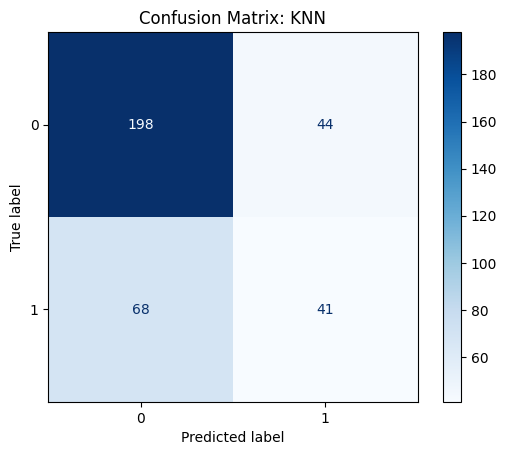

In [65]:
from sklearn.metrics import ConfusionMatrixDisplay
import matplotlib.pyplot as plt

# Find the best model based on F1
best_model_name = results_df.loc[results_df['F1'].idxmax(), 'Model']
best_model = models[best_model_name]

print(f"Best model based on F1: {best_model_name}")

# Create confusion matrix
ConfusionMatrixDisplay.from_estimator(best_model, X_test, y_test, cmap='Blues')
plt.title(f'Confusion Matrix: {best_model_name}')
plt.show()

#### Answer: Which model catches the highest proportion of high-arrears households? What does a missed case mean for SLCM?

Based on the test results, **KNN** catches the highest proportion of high-arrears households, as it has the highest recall (approx. 0.376). For SLCM, a missed case (a false negative) means a household that actually has $3,000 or more in past-due rent goes unidentified by the system, meaning they might not receive proactive outreach or timely assistance.

## 7. Try a small GridSearchCV (15 points)

In [66]:
from sklearn.model_selection import GridSearchCV

# We will use the knn_pipe and rf_pipe created earlier.

In [67]:
# For KNN, try n_neighbors = [3, 5, 7].
knn_param_grid = {'classifier__n_neighbors': [3, 5, 7]}
knn_grid = GridSearchCV(knn_pipe, knn_param_grid, cv=3, scoring='f1')
knn_grid.fit(X_train, y_train)

GridSearchCV(cv=3,
             estimator=Pipeline(steps=[('preprocessor',
                                        ColumnTransformer(transformers=[('num',
                                                                         Pipeline(steps=[('imputer',
                                                                                          SimpleImputer(strategy='median')),
                                                                                         ('scaler',
                                                                                          StandardScaler())]),
                                                                         ['adults_in_household',
                                                                          'children_in_household',
                                                                          'monthly_household_income',
                                                                          'monthly_rent']),
                                                                        ('cat',
                                                                         Pipeline(steps=[('imputer',
                                                                                          SimpleImputer(strategy='most_frequent')),
                                                                                         ('onehot',
                                                                                          OneHotEncoder(handle_unknown='ignore'))]),
                                                                         ['household_has_65plus',
                                                                          'income_sources',
                                                                          'employment_status',
                                                                          'has_housing_voucher',
                                                                          'eviction_in_progress',
                                                                          'behind_on_utilities',
                                                                          'main_reason_behind_on_rent',
                                                                          'intake_quarter'])])),
                                       ('classifier', KNeighborsClassifier())]),
             param_grid={'classifier__n_neighbors': [3, 5, 7]}, scoring='f1')

In [68]:
# For Random Forest, try max_depth = [3, 5, None] (keep n_estimators=100).
rf_param_grid = {'classifier__max_depth': [3, 5, None]}
rf_grid = GridSearchCV(rf_pipe, rf_param_grid, cv=3, scoring='f1')
rf_grid.fit(X_train, y_train)

GridSearchCV(cv=3,
             estimator=Pipeline(steps=[('preprocessor',
                                        ColumnTransformer(transformers=[('num',
                                                                         Pipeline(steps=[('imputer',
                                                                                          SimpleImputer(strategy='median')),
                                                                                         ('scaler',
                                                                                          StandardScaler())]),
                                                                         ['adults_in_household',
                                                                          'children_in_household',
                                                                          'monthly_household_income',
                                                                          'monthly_rent']),
                                                                        ('cat',
                                                                         Pipeline(steps=[('imputer',
                                                                                          SimpleImputer(strategy='most_freque...,
                                                                                         ('onehot',
                                                                                          OneHotEncoder(handle_unknown='ignore'))]),
                                                                         ['household_has_65plus',
                                                                          'income_sources',
                                                                          'employment_status',
                                                                          'has_housing_voucher',
                                                                          'eviction_in_progress',
                                                                          'behind_on_utilities',
                                                                          'main_reason_behind_on_rent',
                                                                          'intake_quarter'])])),
                                       ('classifier',
                                        RandomForestClassifier(random_state=42))]),
             param_grid={'classifier__max_depth': [3, 5, None]}, scoring='f1')

In [69]:
# Print best_params_ and best_score_ for each search.
print("KNN Best Params:", knn_grid.best_params_)
print("KNN Best CV F1 Score:", knn_grid.best_score_)

print("\nRandom Forest Best Params:", rf_grid.best_params_)
print("Random Forest Best CV F1 Score:", rf_grid.best_score_)

KNN Best Params: {'classifier__n_neighbors': 7}
KNN Best CV F1 Score: 0.4854649923374277

Random Forest Best Params: {'classifier__max_depth': None}
Random Forest Best CV F1 Score: 0.4574743145651916


#### Answer: Which has the higher best cross-validation F1? Why is GridSearchCV fitted on training data only?

**KNN** has the higher best cross-validation F1 score (0.485 vs. 0.457 for Random Forest).

We fit GridSearchCV exclusively on the training data to prevent **data leakage**. If we allowed the model to use the test data during hyperparameter tuning, the test set would no longer be a reliable, unbiased measure of how well the model generalizes to completely new, unseen data.

# Part 4 – Explain the Results (15 points)

## 8. Interpret your comparison (8 points)

#### In 4–5 sentences, identify the most promising model based on your results. Explain your choice using F1 and recall, not accuracy alone.

The most promising model based on the initial evaluation is **KNN**. While its accuracy was slightly lower than some other models, accuracy is misleading due to the class imbalance in our data. KNN achieved the highest test F1 score (0.42) and the highest test recall (0.38). This indicates it is the best at balancing precision with the ability to actually find the minority class (households with high arrears), making it the most useful for our objective.

#### Did a more complex model necessarily perform better? What types of errors should SLCM pay attention to?

No, a more complex model did not necessarily perform better; the relatively simple KNN outperformed complex models like Random Forest and SVC in both recall and F1 score. SLCM should pay the most attention to **False Negatives** (missed cases), as these represent highly vulnerable households slipping through the cracks without assistance. However, they also need to be mindful of False Positives if resources and staff time for outreach are strictly limited.

## 9. Recommendation to SLCM (7 points)

#### Write 4–5 sentences for a non-technical SLCM audience: what you tried to predict, how well the selected model performed, one practical insight, and one limitation.

We built a model to predict whether a household is likely to have $3,000 or more in past-due rent based on their basic housing and demographic information. The best model was able to successfully identify about 38% of the households experiencing this severe level of debt in our test data. A practical insight is that while basic household characteristics do hold some predictive signals, they do not tell the whole story of a family's financial distress. A major limitation is that the model misses a significant portion of high-need households, meaning it is not a perfect safety net.

#### State that a prediction is not proof of cause and must not be used alone to decide eligibility for assistance.

A prediction from this model is not proof of cause and **must not be used alone to decide eligibility for assistance**. It is intended solely as an early-warning tool to help prioritize supportive outreach.

### Bonus / Experiment: Checking Categorical Values

In [70]:
# Inspect unique values in our categorical features to ensure we know the exact strings.
for col in categorical_features:
    unique_vals = df[col].dropna().unique()
    print(f"\n--- {col} ---")
    print(unique_vals)


--- household_has_65plus ---
['No' 'Yes' 'Prefer not to answer']

--- income_sources ---
['Food benefits - TANF/SNAP, No income, Other' 'Child support'
 'Food benefits - TANF/SNAP' 'Full-time employment' 'Part-time employment'
 'No income' 'Child support, Food benefits - TANF/SNAP'
 'Food benefits - TANF/SNAP, No income'
 'Part-time employment, Veterans benefits, Social Security - SSI/SSDI, Food benefits - TANF/SNAP, No income'
 'Social Security - SSI/SSDI'
 'Full-time employment, Social Security - SSI/SSDI, Food benefits - TANF/SNAP'
 'Other' 'Food benefits - TANF/SNAP, Other'
 'Spousal support (Alimony), Social Security - SSI/SSDI'
 'Full-time employment, No income' 'Part-time employment, No income'
 'Full-time employment, Food benefits - TANF/SNAP'
 'Social Security - SSI/SSDI, Food benefits - TANF/SNAP, No income'
 'Social Security - SSI/SSDI, Food benefits - TANF/SNAP, Other'
 'Full-time employment, Social Security - SSI/SSDI, Pension'
 'Part-time employment, Food benefits - TANF

### Disclosure
*This project was put together using Gemini 3.1 Pro for coding and grammar correction.*